# Model Training - Rating Classification
**Duplicate-Aware and Cross-Application Evaluation of Sentiment Classification on Indonesian Government Application Reviews**

Eksperimen klasifikasi sentimen (`Positive`, `Negative`, `Neutral`) berbasis TF-IDF (Unigram + Bigram) menggunakan:
1. **Multinomial Naive Bayes (MNB)**
2. **Linear SVM (SGDClassifier, hinge loss)**
3. **Random Forest (RF)**
4. **Majority Baseline (DummyClassifier)**

## 1. Instalasi dan import library

In [9]:
# Jalankan jika library belum tersedia
# %pip install -U pandas numpy scipy scikit-learn matplotlib seaborn joblib

import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import seaborn as sns
except ImportError:
    sns = None

try:
    from IPython.display import display
except ImportError:
    display = print

import joblib

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 1000)

## 2. Konfigurasi dan parameter eksperimen

In [ ]:
# Pencarian jalur data
candidate_paths = [
    Path("../data/Rating_labeled_processed.csv.gz"),
    Path("data/Rating_labeled_processed.csv.gz"),
    Path("Rating_labeled_processed.csv.gz"),
    Path("/content/government-app-sentiment-analysis/data/Rating_labeled_processed.csv.gz"),
    Path("/content/Rating_labeled_processed.csv.gz"),
    Path("../data/Rating_labeled_processed.csv"),
    Path("data/Rating_labeled_processed.csv"),
    Path("Rating_labeled_processed.csv"),
]

DATA_SOURCE = None
for p in candidate_paths:
    if p.exists():
        DATA_SOURCE = p
        break

if DATA_SOURCE is None:
    raise FileNotFoundError(
        "File dataset Rating_labeled_processed.csv tidak ditemukan.\n"
        "Pastikan dataset tersedia di folder data/ atau di direktori kerja saat ini."
    )

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TEXT_COL = "content_clean"       # Fitur teks utama tanpa stopword removal
TARGET_COL = "label"
GROUP_COL = "duplicate_group"
APP_COL = "app"
N_APPS_COL = "n_apps_in_group"

TEST_SIZE = 0.20
MAX_FEATURES = 100_000           # N-gram Unigram + Bigram
MIN_DF = 2
MAX_DF = 0.98
N_JOBS = -1

# Seed untuk evaluasi multi-seed Duplicate-Group Holdout
EVAL_SEEDS = [42, 123, 456, 789, 2024]

# Hyperparameter model
SGD_MAX_ITER = 1000              # Mencegah truncation warning
SGD_TOL = 1e-3
RF_N_ESTIMATORS = 100            # Jumlah estimator Random Forest

# None = gunakan seluruh baris; jika diset angka (misal: 50_000) untuk uji coba, pengambilan sampel dilakukan proporsional per aplikasi
MAX_ROWS = None

print("Data source :", DATA_SOURCE.resolve())
print("Model dir   :", MODEL_DIR.resolve())
print("Seeds list  :", EVAL_SEEDS)

## 3. Baca data dan validasi kolom

In [11]:
read_kwargs = {
    "low_memory": False,
    "on_bad_lines": "skip",       # Melewati baris jika ada koma tak ter-quote atau quotes korup
    "encoding": "utf-8",
    "encoding_errors": "replace"  # Tangani byte karakter non-UTF8 secara aman
}
if DATA_SOURCE.suffix == ".gz":
    df = pd.read_csv(DATA_SOURCE, compression="gzip", **read_kwargs)
else:
    df = pd.read_csv(DATA_SOURCE, **read_kwargs)
print("Ukuran dataset awal:", df.shape)

required = [TEXT_COL, TARGET_COL, GROUP_COL, APP_COL, N_APPS_COL]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing}")

# Buang baris tanpa teks, target, duplicate group, atau nama aplikasi
df = df.dropna(subset=[TEXT_COL, TARGET_COL, GROUP_COL, APP_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df[TARGET_COL] = df[TARGET_COL].astype(str).str.strip()
df[GROUP_COL] = df[GROUP_COL].astype(str)
df[APP_COL] = df[APP_COL].astype(str).str.strip()

df = df[df[TEXT_COL].ne("") & df[TARGET_COL].ne("")]
df = df.reset_index(drop=True)

# Jika ingin smoke-test cepat, lakukan stratified sampling agar seluruh 6 aplikasi tetap terwakili
if MAX_ROWS is not None and len(df) > MAX_ROWS:
    sample_indices = []
    for app_name, app_group in df.groupby(APP_COL):
        n_sample = max(10, int(len(app_group) / len(df) * MAX_ROWS))
        sample_indices.extend(app_group.sample(n=min(len(app_group), n_sample), random_state=RANDOM_STATE).index)
    df = df.loc[sample_indices].reset_index(drop=True)
    print(f"PERINGATAN: Menggunakan stratified subset {len(df):,} baris untuk uji coba cepat.")

unique_apps = sorted(df[APP_COL].unique())
print(f"Ukuran dataset setelah validasi: {df.shape}")
print(f"Aplikasi ditemukan ({len(unique_apps)}): {unique_apps}")

if len(unique_apps) < 2:
    print("\n[PERHATIAN] Dataset yang terbaca hanya memiliki 1 aplikasi!")
    print("File CSV ini tersusun per aplikasi (baris awal didominasi oleh satusehat).")
    print("Jangan gunakan pd.read_csv(..., nrows=...) atau df.head(...) kecil tanpa membaca seluruh aplikasi.")

display(df[[TEXT_COL, TARGET_COL, GROUP_COL, APP_COL, N_APPS_COL]].head())

Ukuran dataset awal: (609900, 12)
Ukuran dataset setelah validasi: (609900, 12)
Aplikasi ditemukan (6): ['BMKG', 'JMO', 'KAI', 'mobileJKN', 'pertamina', 'satusehat']


,content_clean,label,duplicate_group,app,n_apps_in_group
0,lelet,Negative,0,satusehat,5
1,joss,Positive,1,satusehat,6
2,jadi lebih waspada sama bahaya covid 19,Positive,2,satusehat,1
3,saya sudah vaksin kedua tapi sertifikat vaksin...,Negative,3,satusehat,1
4,mantap sangat membantu,Positive,4,satusehat,6


## 4. Eksplorasi label, aplikasi, dan duplikasi

--- Distribusi Label Sentimen ---


,jumlah,persentase
label,,
Positive,329707,54.06
Negative,246033,40.34
Neutral,34160,5.60



--- Distribusi Ulasan per Aplikasi ---


,jumlah,persentase
app,,
JMO,197216,32.34
satusehat,188100,30.84
mobileJKN,120497,19.76
pertamina,95494,15.66
KAI,7285,1.19
BMKG,1308,0.21



--- Statistik Duplicate Groups ---
Total ulasan                : 609,900
Total duplicate_group unik  : 353,798
Ulasan duplikat (>1 ulasan) : 269,041 (44.11%)
Ulasan dengan konflik label : 226,323 (37.11%)


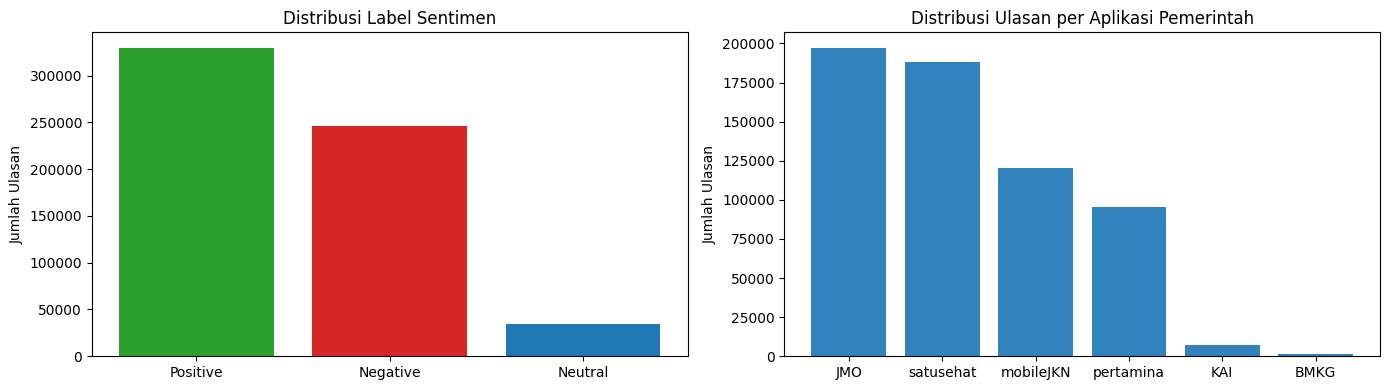

In [12]:
print("--- Distribusi Label Sentimen ---")
label_counts = df[TARGET_COL].value_counts().to_frame("jumlah")
label_counts["persentase"] = (df[TARGET_COL].value_counts(normalize=True) * 100).round(2)
display(label_counts)

print("\n--- Distribusi Ulasan per Aplikasi ---")
app_counts = df[APP_COL].value_counts().to_frame("jumlah")
app_counts["persentase"] = (df[APP_COL].value_counts(normalize=True) * 100).round(2)
display(app_counts)

print("\n--- Statistik Duplicate Groups ---")
n_unique_groups = df[GROUP_COL].nunique()
singleton_rows = (df["group_size"] == 1).sum() if "group_size" in df.columns else (df[GROUP_COL].value_counts() == 1).sum()
duplicate_rows = len(df) - singleton_rows
conflict_rows = df["has_label_conflict"].sum() if "has_label_conflict" in df.columns else 0

print(f"Total ulasan                : {len(df):,}")
print(f"Total duplicate_group unik  : {n_unique_groups:,}")
print(f"Ulasan duplikat (>1 ulasan) : {duplicate_rows:,} ({duplicate_rows/len(df)*100:.2f}%)")
print(f"Ulasan dengan konflik label : {conflict_rows:,} ({conflict_rows/len(df)*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
labels_order = ["Positive", "Negative", "Neutral"]
lbl_counts = df[TARGET_COL].value_counts()
axes[0].bar(labels_order, [lbl_counts.get(l, 0) for l in labels_order], color=["#2ca02c", "#d62728", "#1f77b4"])
axes[0].set_title("Distribusi Label Sentimen")
axes[0].set_ylabel("Jumlah Ulasan")

app_counts_s = df[APP_COL].value_counts()
axes[1].bar(app_counts_s.index, app_counts_s.values, color="#3182bd")
axes[1].set_title("Distribusi Ulasan per Aplikasi Pemerintah")
axes[1].set_ylabel("Jumlah Ulasan")
plt.tight_layout()
plt.show()

## 5. Fungsi evaluasi dan pembangun model

In [13]:
results = []
split_diagnostics = []

def compute_metrics(y_true, y_pred, split_name, model_name, target_app="All", subset="All", seed=None):
    acc = accuracy_score(y_true, y_pred)
    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    classes = ["Negative", "Neutral", "Positive"]
    _, _, f1_per_class, support_per_class = precision_recall_fscore_support(
        y_true, y_pred, labels=classes, zero_division=0
    )

    return {
        "split": split_name,
        "seed": seed,
        "model": model_name,
        "target_app": target_app,
        "subset": subset,
        "n_samples": len(y_true),
        "accuracy": acc,
        "macro_precision": p_macro,
        "macro_recall": r_macro,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted,
        "f1_negative": f1_per_class[0],
        "f1_neutral": f1_per_class[1],
        "f1_positive": f1_per_class[2],
        "support_negative": support_per_class[0],
        "support_neutral": support_per_class[1],
        "support_positive": support_per_class[2]
    }

def get_models(random_state=RANDOM_STATE):
    return {
        "MajorityBaseline": DummyClassifier(strategy="most_frequent"),
        "MultinomialNB": MultinomialNB(alpha=0.5),
        "LinearSVM_SGD": SGDClassifier(
            loss="hinge",
            class_weight="balanced",
            max_iter=SGD_MAX_ITER,
            tol=SGD_TOL,
            random_state=random_state,
            n_jobs=N_JOBS
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=RF_N_ESTIMATORS,
            class_weight="balanced_subsample",
            max_features="sqrt",
            min_samples_leaf=2,
            random_state=random_state,
            n_jobs=N_JOBS
        )
    }

def train_and_eval(name, model, X_train, y_train, X_test, y_test, split_name="holdout", seed=RANDOM_STATE):
    start = time.time()
    if name == "MultinomialNB":
        sw = compute_sample_weight("balanced", y_train)
        model.fit(X_train, y_train, sample_weight=sw)
    else:
        model.fit(X_train, y_train)
    fit_time = time.time() - start

    y_pred = model.predict(X_test)
    m = compute_metrics(y_test, y_pred, split_name, name, seed=seed)
    m["fit_time_seconds"] = round(fit_time, 2)
    results.append(m)

    print(f"\n=== {name} | {split_name} (Fit: {fit_time:.1f}s) ===")
    print(f"Accuracy   : {m['accuracy']:.4f}")
    print(f"Macro F1   : {m['macro_f1']:.4f}")
    print(f"Weighted F1: {m['weighted_f1']:.4f}")
    print(f"F1 Negative: {m['f1_negative']:.4f} | F1 Neutral: {m['f1_neutral']:.4f} | F1 Positive: {m['f1_positive']:.4f}")
    return model, y_pred

## 6. Baseline: Conventional Random Split (RQ1)
Pemisahan acak konvensional (80:20 stratified) untuk mengukur dampak kebocoran teks duplikat ke test set.

In [14]:
# 6.1 Pembagian data secara konvensional (Random Split)
train_df_rnd, test_df_rnd = train_test_split(
    df, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=df[TARGET_COL]
)
train_df_rnd = train_df_rnd.reset_index(drop=True)
test_df_rnd = test_df_rnd.reset_index(drop=True)

# 6.2 Diagnostik Kebocoran Teks Duplikat
train_groups_rnd = set(train_df_rnd[GROUP_COL])
test_groups_rnd = set(test_df_rnd[GROUP_COL])
overlap_groups_rnd = train_groups_rnd.intersection(test_groups_rnd)
test_samples_with_dup_rnd = test_df_rnd[GROUP_COL].isin(train_groups_rnd).sum()
prop_test_dup_rnd = test_samples_with_dup_rnd / len(test_df_rnd)

print("=== DIAGNOSTIK RANDOM SPLIT KONVENSIONAL ===")
print(f"Train samples : {len(train_df_rnd):,} baris")
print(f"Test samples  : {len(test_df_rnd):,} baris")
print(f"Unique groups Train : {len(train_groups_rnd):,}")
print(f"Unique groups Test  : {len(test_groups_rnd):,}")
print(f"Duplicate groups overlap : {len(overlap_groups_rnd):,} grup")
print(f"Test samples dengan teks duplikat di Train : {test_samples_with_dup_rnd:,} ({prop_test_dup_rnd*100:.2f}%)")

split_diagnostics.append({
    "split_type": "Random Split (Conventional)",
    "seed": RANDOM_STATE,
    "train_rows": len(train_df_rnd),
    "test_rows": len(test_df_rnd),
    "train_unique_groups": len(train_groups_rnd),
    "test_unique_groups": len(test_groups_rnd),
    "overlapping_groups": len(overlap_groups_rnd),
    "test_samples_with_train_duplicate": test_samples_with_dup_rnd,
    "test_samples_duplicate_pct": prop_test_dup_rnd * 100,
    "train_pos_pct": (train_df_rnd[TARGET_COL] == "Positive").mean() * 100,
    "train_neg_pct": (train_df_rnd[TARGET_COL] == "Negative").mean() * 100,
    "train_neu_pct": (train_df_rnd[TARGET_COL] == "Neutral").mean() * 100,
    "test_pos_pct": (test_df_rnd[TARGET_COL] == "Positive").mean() * 100,
    "test_neg_pct": (test_df_rnd[TARGET_COL] == "Negative").mean() * 100,
    "test_neu_pct": (test_df_rnd[TARGET_COL] == "Neutral").mean() * 100,
})

# 6.3 Ekstraksi Fitur TF-IDF (Hanya Fit pada Train)
print("\nFitting TF-IDF pada Train data Random Split...")
vec_rnd = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)
X_train_rnd = vec_rnd.fit_transform(train_df_rnd[TEXT_COL])
X_test_rnd = vec_rnd.transform(test_df_rnd[TEXT_COL])
y_train_rnd = train_df_rnd[TARGET_COL].to_numpy()
y_test_rnd = test_df_rnd[TARGET_COL].to_numpy()
print(f"TF-IDF selesai. Jumlah fitur: {X_train_rnd.shape[1]:,}")

# 6.4 Training dan Evaluasi 4 Model
random_split_results = []
rnd_models = get_models(RANDOM_STATE)
rnd_preds = {}

for name, model in rnd_models.items():
    fitted_m, pred = train_and_eval(name, model, X_train_rnd, y_train_rnd, X_test_rnd, y_test_rnd, split_name="RandomSplit")
    rnd_preds[name] = pred
    m_dict = compute_metrics(y_test_rnd, pred, "RandomSplit", name, seed=RANDOM_STATE)
    random_split_results.append(m_dict)

random_split_df = pd.DataFrame(random_split_results).sort_values("macro_f1", ascending=False)
display(random_split_df[["model", "accuracy", "macro_f1", "weighted_f1", "f1_negative", "f1_neutral", "f1_positive"]])

=== DIAGNOSTIK RANDOM SPLIT KONVENSIONAL ===
Train samples : 487,920 baris
Test samples  : 121,980 baris
Unique groups Train : 285,639
Unique groups Test  : 74,867
Duplicate groups overlap : 6,708 grup
Test samples dengan teks duplikat di Train : 53,535 (43.89%)

Fitting TF-IDF pada Train data Random Split...
TF-IDF selesai. Jumlah fitur: 100,000

=== MajorityBaseline | RandomSplit (Fit: 0.2s) ===
Accuracy   : 0.5406
Macro F1   : 0.2339
Weighted F1: 0.3794
F1 Negative: 0.0000 | F1 Neutral: 0.0000 | F1 Positive: 0.7018

=== MultinomialNB | RandomSplit (Fit: 1.5s) ===
Accuracy   : 0.8048
Macro F1   : 0.6607
Weighted F1: 0.8352
F1 Negative: 0.8242 | F1 Neutral: 0.2544 | F1 Positive: 0.9036

=== LinearSVM_SGD | RandomSplit (Fit: 2.3s) ===
Accuracy   : 0.8667
Macro F1   : 0.6453
Weighted F1: 0.8543
F1 Negative: 0.8760 | F1 Neutral: 0.1485 | F1 Positive: 0.9113

=== RandomForest | RandomSplit (Fit: 615.6s) ===
Accuracy   : 0.8414
Macro F1   : 0.6599
Weighted F1: 0.8456
F1 Negative: 0.8601 | 

,model,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
1,MultinomialNB,0.804755,0.660728,0.835205,0.824204,0.254388,0.903591
3,RandomForest,0.841392,0.659853,0.845586,0.860071,0.219883,0.899605
2,LinearSVM_SGD,0.866650,0.645289,0.854350,0.876008,0.148543,0.911315
0,MajorityBaseline,0.540589,0.233932,0.379382,0.000000,0.000000,0.701795


## 7. Duplicate-Group Holdout (RQ1)
Pemisahan berbasis `duplicate_group` (`GroupShuffleSplit` 80:20) untuk menjamin nol kebocoran duplikat (`overlap == 0`).

In [15]:
# 7.1 Duplicate-Group Holdout Split (Seed 42)
splitter_42 = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)
train_idx_grp, test_idx_grp = next(
    splitter_42.split(df, y=df[TARGET_COL], groups=df[GROUP_COL])
)

train_df_grp = df.iloc[train_idx_grp].reset_index(drop=True)
test_df_grp = df.iloc[test_idx_grp].reset_index(drop=True)

train_groups_grp = set(train_df_grp[GROUP_COL])
test_groups_grp = set(test_df_grp[GROUP_COL])
overlap_grp = train_groups_grp.intersection(test_groups_grp)

print("=== DIAGNOSTIK DUPLICATE-GROUP HOLDOUT (SEED 42) ===")
print(f"Train samples : {len(train_df_grp):,} baris")
print(f"Test samples  : {len(test_df_grp):,} baris")
print(f"Group overlap : {len(overlap_grp)} (Harus 0)")
assert len(overlap_grp) == 0, "Kebocoran duplicate group terdeteksi!"

split_diagnostics.append({
    "split_type": "Duplicate-Group Holdout",
    "seed": RANDOM_STATE,
    "train_rows": len(train_df_grp),
    "test_rows": len(test_df_grp),
    "train_unique_groups": len(train_groups_grp),
    "test_unique_groups": len(test_groups_grp),
    "overlapping_groups": 0,
    "test_samples_with_train_duplicate": 0,
    "test_samples_duplicate_pct": 0.0,
    "train_pos_pct": (train_df_grp[TARGET_COL] == "Positive").mean() * 100,
    "train_neg_pct": (train_df_grp[TARGET_COL] == "Negative").mean() * 100,
    "train_neu_pct": (train_df_grp[TARGET_COL] == "Neutral").mean() * 100,
    "test_pos_pct": (test_df_grp[TARGET_COL] == "Positive").mean() * 100,
    "test_neg_pct": (test_df_grp[TARGET_COL] == "Negative").mean() * 100,
    "test_neu_pct": (test_df_grp[TARGET_COL] == "Neutral").mean() * 100,
})

print("\nDistribusi label train:")
display(train_df_grp[TARGET_COL].value_counts().to_frame("jumlah"))
print("\nDistribusi label test:")
display(test_df_grp[TARGET_COL].value_counts().to_frame("jumlah"))

# 7.2 Ekstraksi Fitur TF-IDF pada Group Train Data
print("\nFitting TF-IDF pada Group Holdout Train...")
vec_grp = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=MAX_FEATURES,
    min_df=MIN_DF,
    max_df=MAX_DF,
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)
X_train_grp = vec_grp.fit_transform(train_df_grp[TEXT_COL])
X_test_grp = vec_grp.transform(test_df_grp[TEXT_COL])
y_train_grp = train_df_grp[TARGET_COL].to_numpy()
y_test_grp = test_df_grp[TARGET_COL].to_numpy()
print(f"TF-IDF selesai. X_train: {X_train_grp.shape}, X_test: {X_test_grp.shape}")

# 7.3 Training dan Evaluasi Model pada Group Holdout
group_holdout_results = []
grp_models = get_models(RANDOM_STATE)
grp_preds = {}
trained_models = {}

for name, model in grp_models.items():
    fitted_m, pred = train_and_eval(name, model, X_train_grp, y_train_grp, X_test_grp, y_test_grp, split_name="GroupHoldout_Seed42")
    grp_preds[name] = pred
    trained_models[name] = fitted_m
    m_dict = compute_metrics(y_test_grp, pred, "GroupHoldout_Seed42", name, seed=RANDOM_STATE)
    group_holdout_results.append(m_dict)

group_holdout_df = pd.DataFrame(group_holdout_results).sort_values("macro_f1", ascending=False)
display(group_holdout_df[["model", "accuracy", "macro_f1", "weighted_f1", "f1_negative", "f1_neutral", "f1_positive"]])

=== DIAGNOSTIK DUPLICATE-GROUP HOLDOUT (SEED 42) ===
Train samples : 488,458 baris
Test samples  : 121,442 baris
Group overlap : 0 (Harus 0)

Distribusi label train:


,jumlah
label,
Positive,263622
Negative,197192
Neutral,27644



Distribusi label test:


,jumlah
label,
Positive,66085
Negative,48841
Neutral,6516



Fitting TF-IDF pada Group Holdout Train...
TF-IDF selesai. X_train: (488458, 100000), X_test: (121442, 100000)

=== MajorityBaseline | GroupHoldout_Seed42 (Fit: 0.3s) ===
Accuracy   : 0.5442
Macro F1   : 0.2349
Weighted F1: 0.3835
F1 Negative: 0.0000 | F1 Neutral: 0.0000 | F1 Positive: 0.7048

=== MultinomialNB | GroupHoldout_Seed42 (Fit: 1.6s) ===
Accuracy   : 0.8021
Macro F1   : 0.6547
Weighted F1: 0.8320
F1 Negative: 0.8170 | F1 Neutral: 0.2463 | F1 Positive: 0.9009

=== LinearSVM_SGD | GroupHoldout_Seed42 (Fit: 2.2s) ===
Accuracy   : 0.8687
Macro F1   : 0.6362
Weighted F1: 0.8554
F1 Negative: 0.8742 | F1 Neutral: 0.1204 | F1 Positive: 0.9139

=== RandomForest | GroupHoldout_Seed42 (Fit: 575.7s) ===
Accuracy   : 0.8433
Macro F1   : 0.6532
Weighted F1: 0.8460
F1 Negative: 0.8559 | F1 Neutral: 0.2014 | F1 Positive: 0.9023


,model,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
1,MultinomialNB,0.802078,0.654746,0.832039,0.817019,0.246329,0.900892
3,RandomForest,0.843250,0.653204,0.846044,0.855865,0.201400,0.902347
2,LinearSVM_SGD,0.868744,0.636163,0.855351,0.874243,0.120389,0.913856
0,MajorityBaseline,0.544169,0.234935,0.383533,0.000000,0.000000,0.704805


### 7.1 Perbandingan Random Split vs Duplicate-Group Holdout (RQ1)

=== TABEL PERBANDINGAN RQ1: RANDOM SPLIT VS DUPLICATE-GROUP HOLDOUT ===


,Model,Random_Accuracy,Group_Accuracy,Delta_Accuracy,Random_Macro_F1,Group_Macro_F1,Delta_Macro_F1,Random_Weighted_F1,Group_Weighted_F1,Delta_Weighted_F1
0,MajorityBaseline,0.540589,0.544169,0.003581,0.233932,0.234935,0.001003,0.379382,0.383533,0.004151
1,MultinomialNB,0.804755,0.802078,-0.002677,0.660728,0.654746,-0.005981,0.835205,0.832039,-0.003166
2,LinearSVM_SGD,0.866650,0.868744,0.002094,0.645289,0.636163,-0.009126,0.854350,0.855351,0.001001
3,RandomForest,0.841392,0.843250,0.001858,0.659853,0.653204,-0.006649,0.845586,0.846044,0.000458


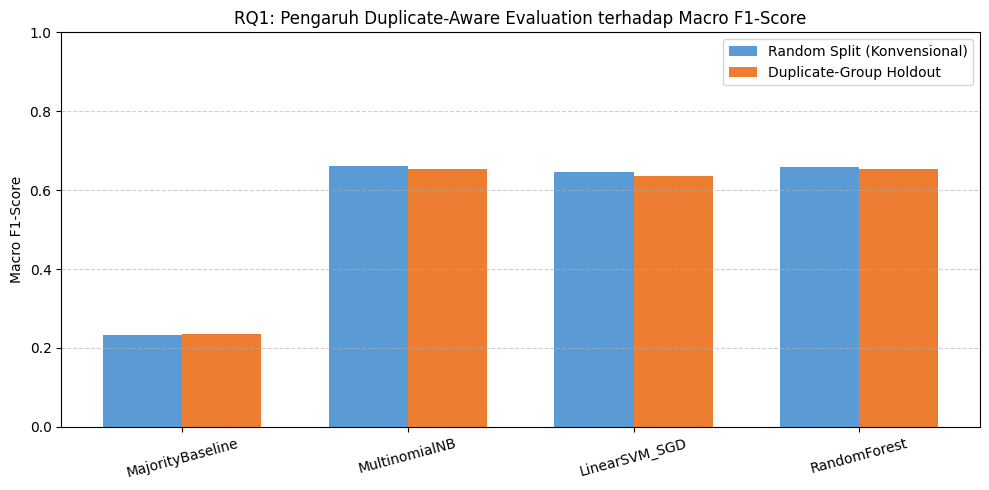

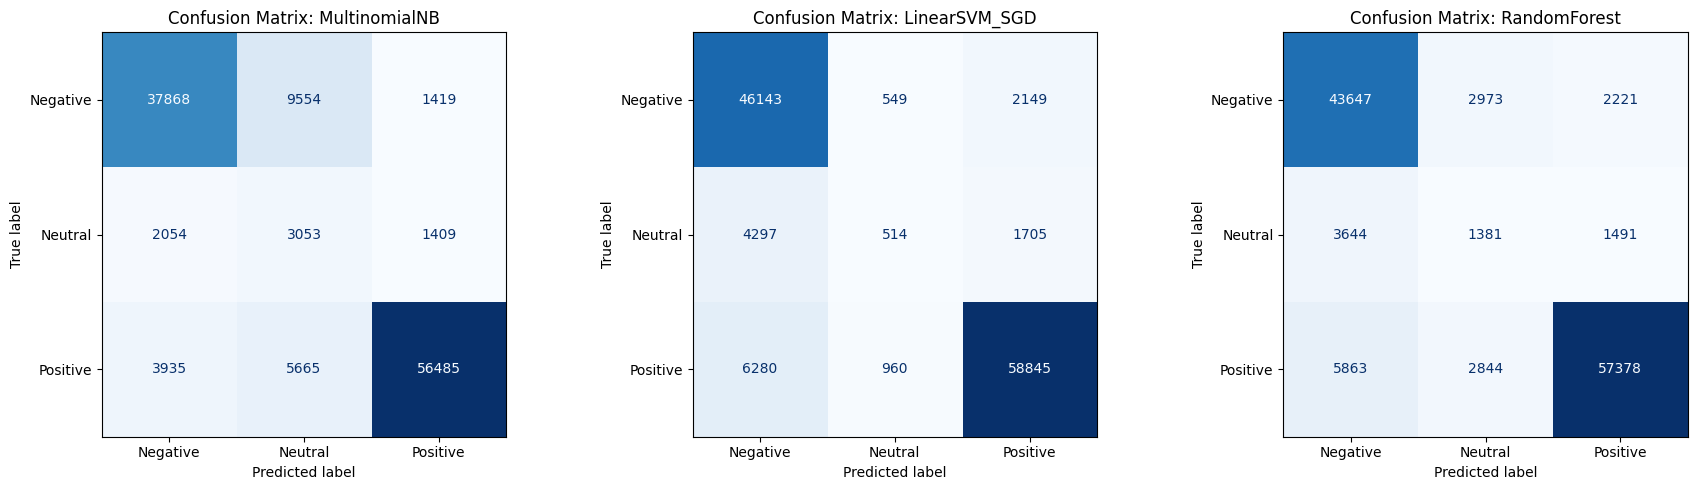

In [16]:
# Perbandingan performa Random Split vs Duplicate-Group Holdout (Seed 42)
rq1_comparison = []
for m_name in grp_models.keys():
    r_rnd = random_split_df[random_split_df["model"] == m_name].iloc[0]
    r_grp = group_holdout_df[group_holdout_df["model"] == m_name].iloc[0]
    rq1_comparison.append({
        "Model": m_name,
        "Random_Accuracy": r_rnd["accuracy"],
        "Group_Accuracy": r_grp["accuracy"],
        "Delta_Accuracy": r_grp["accuracy"] - r_rnd["accuracy"],
        "Random_Macro_F1": r_rnd["macro_f1"],
        "Group_Macro_F1": r_grp["macro_f1"],
        "Delta_Macro_F1": r_grp["macro_f1"] - r_rnd["macro_f1"],
        "Random_Weighted_F1": r_rnd["weighted_f1"],
        "Group_Weighted_F1": r_grp["weighted_f1"],
        "Delta_Weighted_F1": r_grp["weighted_f1"] - r_rnd["weighted_f1"]
    })

rq1_comp_df = pd.DataFrame(rq1_comparison)
print("=== TABEL PERBANDINGAN RQ1: RANDOM SPLIT VS DUPLICATE-GROUP HOLDOUT ===")
display(rq1_comp_df)

# Visualisasi Perbandingan Macro F1
plt.figure(figsize=(10, 5))
x = np.arange(len(rq1_comp_df))
width = 0.35

plt.bar(x - width/2, rq1_comp_df["Random_Macro_F1"], width, label="Random Split (Konvensional)", color="#5B9BD5")
plt.bar(x + width/2, rq1_comp_df["Group_Macro_F1"], width, label="Duplicate-Group Holdout", color="#ED7D31")

plt.ylabel("Macro F1-Score")
plt.title("RQ1: Pengaruh Duplicate-Aware Evaluation terhadap Macro F1-Score")
plt.xticks(x, rq1_comp_df["Model"], rotation=15)
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Confusion Matrices untuk Model Utama pada Group Holdout
labels = sorted(pd.Series(y_test_grp).unique())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (m_name, pred) in enumerate([(k, grp_preds[k]) for k in ["MultinomialNB", "LinearSVM_SGD", "RandomForest"]]):
    cm = confusion_matrix(y_test_grp, pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap="Blues", ax=axes[idx], colorbar=False)
    axes[idx].set_title(f"Confusion Matrix: {m_name}")
plt.tight_layout()
plt.show()

### 7.2 Multi-Seed Duplicate Holdout (5 Seeds)
Evaluasi stabilitas holdout pada seed: `[42, 123, 456, 789, 2024]` (`Mean ± Std`).

In [17]:
multiseed_runs = []
print(f"Menjalankan Duplicate Holdout pada 5 Seeds: {EVAL_SEEDS} ...")

for seed in EVAL_SEEDS:
    sp = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=seed)
    tr_idx, te_idx = next(sp.split(df, y=df[TARGET_COL], groups=df[GROUP_COL]))
    tr_df = df.iloc[tr_idx].reset_index(drop=True)
    te_df = df.iloc[te_idx].reset_index(drop=True)

    assert len(set(tr_df[GROUP_COL]).intersection(set(te_df[GROUP_COL]))) == 0

    split_diagnostics.append({
        "split_type": f"Duplicate-Group Holdout (Seed {seed})",
        "seed": seed,
        "train_rows": len(tr_df),
        "test_rows": len(te_df),
        "train_unique_groups": tr_df[GROUP_COL].nunique(),
        "test_unique_groups": te_df[GROUP_COL].nunique(),
        "overlapping_groups": 0,
        "test_samples_with_train_duplicate": 0,
        "test_samples_duplicate_pct": 0.0,
        "train_pos_pct": (tr_df[TARGET_COL] == "Positive").mean() * 100,
        "train_neg_pct": (tr_df[TARGET_COL] == "Negative").mean() * 100,
        "train_neu_pct": (tr_df[TARGET_COL] == "Neutral").mean() * 100,
        "test_pos_pct": (te_df[TARGET_COL] == "Positive").mean() * 100,
        "test_neg_pct": (te_df[TARGET_COL] == "Negative").mean() * 100,
        "test_neu_pct": (te_df[TARGET_COL] == "Neutral").mean() * 100,
    })

    vec_s = TfidfVectorizer(
        ngram_range=(1, 2), max_features=MAX_FEATURES, min_df=MIN_DF, max_df=MAX_DF,
        sublinear_tf=True, strip_accents="unicode", dtype=np.float32
    )
    X_tr_s = vec_s.fit_transform(tr_df[TEXT_COL])
    X_te_s = vec_s.transform(te_df[TEXT_COL])
    y_tr_s = tr_df[TARGET_COL].to_numpy()
    y_te_s = te_df[TARGET_COL].to_numpy()

    models_s = {
        "MultinomialNB": MultinomialNB(alpha=0.5),
        "LinearSVM_SGD": SGDClassifier(
            loss="hinge", class_weight="balanced", max_iter=SGD_MAX_ITER, tol=SGD_TOL,
            random_state=seed, n_jobs=N_JOBS
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=RF_N_ESTIMATORS, class_weight="balanced_subsample", max_features="sqrt",
            min_samples_leaf=2, random_state=seed, n_jobs=N_JOBS
        )
    }

    for m_name, model in models_s.items():
        if m_name == "MultinomialNB":
            sw = compute_sample_weight("balanced", y_tr_s)
            model.fit(X_tr_s, y_tr_s, sample_weight=sw)
        else:
            model.fit(X_tr_s, y_tr_s)
        pred = model.predict(X_te_s)
        m_res = compute_metrics(y_te_s, pred, "GroupHoldout_MultiSeed", m_name, seed=seed)
        multiseed_runs.append(m_res)

multiseed_runs_df = pd.DataFrame(multiseed_runs)

# Rekapitulasi Mean +- Std
summary_rows = []
for m_name in ["MultinomialNB", "LinearSVM_SGD", "RandomForest"]:
    sub = multiseed_runs_df[multiseed_runs_df["model"] == m_name]
    summary_rows.append({
        "Model": m_name,
        "Seeds": len(sub),
        "Accuracy_Mean_Std": f"{sub['accuracy'].mean():.4f} ± {sub['accuracy'].std():.4f}",
        "Macro_F1_Mean_Std": f"{sub['macro_f1'].mean():.4f} ± {sub['macro_f1'].std():.4f}",
        "Weighted_F1_Mean_Std": f"{sub['weighted_f1'].mean():.4f} ± {sub['weighted_f1'].std():.4f}",
        "F1_Negative_Mean_Std": f"{sub['f1_negative'].mean():.4f} ± {sub['f1_negative'].std():.4f}",
        "F1_Neutral_Mean_Std": f"{sub['f1_neutral'].mean():.4f} ± {sub['f1_neutral'].std():.4f}",
        "F1_Positive_Mean_Std": f"{sub['f1_positive'].mean():.4f} ± {sub['f1_positive'].std():.4f}"
    })

multiseed_summary_df = pd.DataFrame(summary_rows)
print("=== HASIL DUPLICATE HOLDOUT 5 SEEDS (MEAN ± STD) ===")
display(multiseed_summary_df)

Menjalankan Duplicate Holdout pada 5 Seeds: [42, 123, 456, 789, 2024] ...
=== HASIL DUPLICATE HOLDOUT 5 SEEDS (MEAN ± STD) ===


,Model,Seeds,Accuracy_Mean_Std,Macro_F1_Mean_Std,Weighted_F1_Mean_Std,F1_Negative_Mean_Std,F1_Neutral_Mean_Std,F1_Positive_Mean_Std
0,MultinomialNB,5,0.7827 ± 0.0263,0.6504 ± 0.0078,0.8166 ± 0.0191,0.8188 ± 0.0060,0.2542 ± 0.0049,0.8782 ± 0.0322
1,LinearSVM_SGD,5,0.8538 ± 0.0163,0.6408 ± 0.0052,0.8414 ± 0.0156,0.8731 ± 0.0022,0.1563 ± 0.0281,0.8929 ± 0.0269
2,RandomForest,5,0.8220 ± 0.0208,0.6484 ± 0.0078,0.8278 ± 0.0188,0.8542 ± 0.0034,0.2167 ± 0.0151,0.8744 ± 0.0332


## 8. Leave-One-App-Out / LOAO (RQ2)
Evaluasi generalisasi pada 6 aplikasi pemerintah secara bergantian sebagai target test.

In [18]:
def run_loao_all_models(data, app_col=APP_COL, text_col=TEXT_COL, target_col=TARGET_COL,
                        group_col=GROUP_COL, n_apps_col=N_APPS_COL, max_features=MAX_FEATURES):
    apps = sorted(data[app_col].dropna().astype(str).unique())

    # Validasi awal: LOAO memerlukan minimal 2 aplikasi agar fold train tidak kosong
    if len(apps) < 2:
        print(f"PERINGATAN: LOAO membutuhkan minimal 2 aplikasi berbeda. Data saat ini hanya memiliki: {apps}")
        print("Pastikan seluruh dataset dimuat (jangan gunakan read_csv dengan nrows kecil atau df.head()).")
        return pd.DataFrame()

    loao_records = []

    for fold_i, target_app in enumerate(apps, start=1):
        print(f"\n===== LOAO Fold {fold_i}/{len(apps)}: Test App = {target_app} =====")
        target_mask = data[app_col].astype(str).eq(target_app)
        fold_test = data[target_mask].copy().reset_index(drop=True)
        fold_train = data[~target_mask].copy().reset_index(drop=True)

        # Guard clause: jika train atau test kosong, lewati
        if fold_train.empty or fold_test.empty:
            print(f"Fold dilewati: data train ({len(fold_train)}) atau test ({len(fold_test)}) kosong.")
            continue

        train_groups_fold = set(fold_train[group_col])
        test_groups_fold = set(fold_test[group_col])
        overlap_cnt = fold_test[group_col].isin(train_groups_fold).sum()

        split_diagnostics.append({
            "split_type": f"LOAO Fold ({target_app})",
            "seed": RANDOM_STATE,
            "train_rows": len(fold_train),
            "test_rows": len(fold_test),
            "train_unique_groups": len(train_groups_fold),
            "test_unique_groups": len(test_groups_fold),
            "overlapping_groups": len(train_groups_fold.intersection(test_groups_fold)),
            "test_samples_with_train_duplicate": overlap_cnt,
            "test_samples_duplicate_pct": (overlap_cnt / len(fold_test)) * 100,
            "train_pos_pct": (fold_train[target_col] == "Positive").mean() * 100,
            "train_neg_pct": (fold_train[target_col] == "Negative").mean() * 100,
            "train_neu_pct": (fold_train[target_col] == "Neutral").mean() * 100,
            "test_pos_pct": (fold_test[target_col] == "Positive").mean() * 100,
            "test_neg_pct": (fold_test[target_col] == "Negative").mean() * 100,
            "test_neu_pct": (fold_test[target_col] == "Neutral").mean() * 100,
        })

        # Fit vectorizer hanya pada train fold
        fold_vectorizer = TfidfVectorizer(
            ngram_range=(1, 2), max_features=max_features, min_df=MIN_DF, max_df=MAX_DF,
            sublinear_tf=True, strip_accents="unicode", dtype=np.float32
        )
        Xtr = fold_vectorizer.fit_transform(fold_train[text_col].astype(str))
        Xte = fold_vectorizer.transform(fold_test[text_col].astype(str))
        ytr = fold_train[target_col].astype(str).to_numpy()
        yte = fold_test[target_col].astype(str).to_numpy()

        models_dict = get_models(RANDOM_STATE)

        for m_name, model in models_dict.items():
            t0 = time.time()
            if m_name == "MultinomialNB":
                sw = compute_sample_weight("balanced", ytr)
                model.fit(Xtr, ytr, sample_weight=sw)
            else:
                model.fit(Xtr, ytr)
            fit_t = time.time() - t0
            pred = model.predict(Xte)

            m_res = compute_metrics(yte, pred, "LOAO", m_name, target_app=target_app, subset="Overall_App")
            m_res["train_rows"] = len(fold_train)
            m_res["test_rows"] = len(fold_test)
            m_res["fit_time_seconds"] = round(fit_t, 2)

            # Evaluasi subset murni n_apps_in_group == 1
            pure_mask = fold_test[n_apps_col].astype(float).eq(1).to_numpy()
            if pure_mask.sum() > 0:
                m_pure = compute_metrics(yte[pure_mask], pred[pure_mask], "LOAO", m_name, target_app=target_app, subset="Strict_n_apps_eq_1")
                m_res["pure_test_rows"] = pure_mask.sum()
                m_res["pure_macro_f1"] = m_pure["macro_f1"]
                m_res["pure_accuracy"] = m_pure["accuracy"]
            else:
                m_res["pure_test_rows"] = 0
                m_res["pure_macro_f1"] = np.nan
                m_res["pure_accuracy"] = np.nan

            loao_records.append(m_res)
            print(f"  [{target_app:10s}] {m_name:16s}: Macro F1 = {m_res['macro_f1']:.4f}, Acc = {m_res['accuracy']:.4f}")

    return pd.DataFrame(loao_records)

loao_results_df = run_loao_all_models(df)
if not loao_results_df.empty:
    display(loao_results_df[["target_app", "model", "test_rows", "accuracy", "macro_f1", "weighted_f1", "f1_negative", "f1_neutral", "f1_positive"]])

    # Rata-rata Cross-Application Macro F1 per Model
    loao_summary = loao_results_df.groupby("model").agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std")
    ).reset_index().sort_values("mean_macro_f1", ascending=False)

    print("\n=== REKAPITULASI RATA-RATA CROSS-APPLICATION (LOAO) ===")
    display(loao_summary)


===== LOAO Fold 1/6: Test App = BMKG =====
  [BMKG      ] MajorityBaseline: Macro F1 = 0.3044, Acc = 0.8402
  [BMKG      ] MultinomialNB   : Macro F1 = 0.4634, Acc = 0.7584
  [BMKG      ] LinearSVM_SGD   : Macro F1 = 0.5147, Acc = 0.8234
  [BMKG      ] RandomForest    : Macro F1 = 0.5220, Acc = 0.8050

===== LOAO Fold 2/6: Test App = JMO =====
  [JMO       ] MajorityBaseline: Macro F1 = 0.1222, Acc = 0.2244
  [JMO       ] MultinomialNB   : Macro F1 = 0.6329, Acc = 0.8348
  [JMO       ] LinearSVM_SGD   : Macro F1 = 0.6319, Acc = 0.8807
  [JMO       ] RandomForest    : Macro F1 = 0.6563, Acc = 0.8747

===== LOAO Fold 3/6: Test App = KAI =====
  [KAI       ] MajorityBaseline: Macro F1 = 0.2081, Acc = 0.4538
  [KAI       ] MultinomialNB   : Macro F1 = 0.6219, Acc = 0.7002
  [KAI       ] LinearSVM_SGD   : Macro F1 = 0.6107, Acc = 0.7817
  [KAI       ] RandomForest    : Macro F1 = 0.6218, Acc = 0.7546

===== LOAO Fold 4/6: Test App = mobileJKN =====
  [mobileJKN ] MajorityBaseline: Macro F1

,target_app,model,test_rows,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,BMKG,MajorityBaseline,1308,0.840214,0.304390,0.767258,0.000000,0.000000,0.913170
1,BMKG,MultinomialNB,1308,0.758410,0.463398,0.773341,0.283186,0.236220,0.870787
2,BMKG,LinearSVM_SGD,1308,0.823394,0.514652,0.813413,0.381743,0.255319,0.906893
3,BMKG,RandomForest,1308,0.805046,0.522020,0.806368,0.373832,0.296651,0.895577
4,JMO,MajorityBaseline,197216,0.224363,0.122166,0.082229,0.366498,0.000000,0.000000
5,JMO,MultinomialNB,197216,0.834841,0.632902,0.860969,0.761317,0.207043,0.930346
6,JMO,LinearSVM_SGD,197216,0.880699,0.631886,0.873401,0.817831,0.144080,0.933747
7,JMO,RandomForest,197216,0.874675,0.656337,0.878494,0.823933,0.210171,0.934909
8,KAI,MajorityBaseline,7285,0.453809,0.208101,0.283315,0.000000,0.000000,0.624304
9,KAI,MultinomialNB,7285,0.700206,0.621895,0.729368,0.754420,0.306683,0.804582



=== REKAPITULASI RATA-RATA CROSS-APPLICATION (LOAO) ===


,model,mean_macro_f1,std_macro_f1,mean_accuracy,std_accuracy
3,RandomForest,0.614563,0.049448,0.812607,0.039586
2,MultinomialNB,0.604642,0.069768,0.776533,0.048794
0,LinearSVM_SGD,0.604037,0.047093,0.835663,0.033631
1,MajorityBaseline,0.202302,0.070060,0.464178,0.229140


## 10. Rekapitulasi hasil dan export ke CSV
Ekspor seluruh tabel hasil ke folder `models/` dan sintesis tabel ringkasan.

In [23]:

import os

print("Drive exists:", os.path.exists("/content/drive"))
print("MyDrive exists:", os.path.exists("/content/drive/MyDrive"))
print("Isi /content/drive:", os.listdir("/content/drive")[:10])


Drive exists: True
MyDrive exists: True
Isi /content/drive: ['MyDrive']


In [26]:

from pathlib import Path

MODEL_DIR = Path('/content/drive/MyDrive/IGAR_Results')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Folder hasil:", MODEL_DIR)

# MODEL_DIR sudah terdefinisi
random_split_df.to_csv(
    MODEL_DIR / "random_split_results.csv", index=False
)
group_holdout_df.to_csv(
    MODEL_DIR / "group_holdout_results.csv", index=False
)
multiseed_runs_df.to_csv(
    MODEL_DIR / "group_holdout_multiseed_runs.csv", index=False
)
multiseed_summary_df.to_csv(
    MODEL_DIR / "group_holdout_multiseed_summary.csv", index=False
)
loao_results_df.to_csv(
    MODEL_DIR / "loao_results.csv", index=False
)


Folder hasil: /content/drive/MyDrive/IGAR_Results


In [27]:
# ==========================================
# 1. TABEL DIAGNOSTIK SPLIT
# ==========================================
diag_df = (
    pd.DataFrame(split_diagnostics)
    if 'split_diagnostics' in globals()
    else pd.DataFrame()
)

diag_df.to_csv(
    MODEL_DIR / "split_diagnostics.csv", index=False
)

# ==========================================
# 2. SINTESIS MASTER SUMMARY PAPER TABLE
# ==========================================
summary_paper_rows = []

# ---- A. Conventional Random Split ----
for _, r in random_split_df.iterrows():
    summary_paper_rows.append({
        "Evaluation_Protocol": "Conventional Random Split",
        "Model": r["model"],
        "Target_Scope": "General Test Split (20%)",
        "Accuracy": f'{r["accuracy"]:.4f}',
        "Macro_F1": f'{r["macro_f1"]:.4f}',
        "Weighted_F1": f'{r["weighted_f1"]:.4f}',
        "F1_Negative": f'{r["f1_negative"]:.4f}',
        "F1_Neutral": f'{r["f1_neutral"]:.4f}',
        "F1_Positive": f'{r["f1_positive"]:.4f}',
        "Notes": (
            f"Duplicate leakage = "
            f"{prop_test_dup_rnd*100:.2f}%"
        )
    })

# ---- B. Duplicate-Group Holdout (Seed 42) ----
for _, r in group_holdout_df.iterrows():
    summary_paper_rows.append({
        "Evaluation_Protocol": "Duplicate-Group Holdout (Seed 42)",
        "Model": r["model"],
        "Target_Scope": "Disjoint Duplicate Groups (20%)",
        "Accuracy": f'{r["accuracy"]:.4f}',
        "Macro_F1": f'{r["macro_f1"]:.4f}',
        "Weighted_F1": f'{r["weighted_f1"]:.4f}',
        "F1_Negative": f'{r["f1_negative"]:.4f}',
        "F1_Neutral": f'{r["f1_neutral"]:.4f}',
        "F1_Positive": f'{r["f1_positive"]:.4f}',
        "Notes": "Duplicate leakage = 0.00% (Group-disjoint)"
    })

# ---- C. Duplicate-Group Holdout (5 Seeds) ----
for _, r in multiseed_summary_df.iterrows():
    summary_paper_rows.append({
        "Evaluation_Protocol": "Duplicate-Group Holdout (5 Seeds)",
        "Model": r["Model"],
        "Target_Scope": "5 Seeds Average",
        "Accuracy": r["Accuracy_Mean_Std"],
        "Macro_F1": r["Macro_F1_Mean_Std"],
        "Weighted_F1": r["Weighted_F1_Mean_Std"],
        "F1_Negative": r["F1_Negative_Mean_Std"],
        "F1_Neutral": r["F1_Neutral_Mean_Std"],
        "F1_Positive": r["F1_Positive_Mean_Std"],
        "Notes": "Seeds: 42, 123, 456, 789, 2024"
    })

# ---- D. LOAO Cross-App (RQ2) ----
if not loao_results_df.empty:
    for m_name in [
        "MajorityBaseline",
        "MultinomialNB",
        "LinearSVM_SGD",
        "RandomForest"
    ]:
        sub_loao = loao_results_df[
            loao_results_df["model"] == m_name
        ]

        if not sub_loao.empty:
            summary_paper_rows.append({
                "Evaluation_Protocol": "LOAO Cross-App (6 Apps)",
                "Model": m_name,
                "Target_Scope": "Unseen Government Applications",
                "Accuracy": (
                    f'{sub_loao["accuracy"].mean():.4f} '
                    f'± {sub_loao["accuracy"].std():.4f}'
                ),
                "Macro_F1": (
                    f'{sub_loao["macro_f1"].mean():.4f} '
                    f'± {sub_loao["macro_f1"].std():.4f}'
                ),
                "Weighted_F1": (
                    f'{sub_loao["weighted_f1"].mean():.4f} '
                    f'± {sub_loao["weighted_f1"].std():.4f}'
                ),
                "F1_Negative": (
                    f'{sub_loao["f1_negative"].mean():.4f} '
                    f'± {sub_loao["f1_negative"].std():.4f}'
                ),
                "F1_Neutral": (
                    f'{sub_loao["f1_neutral"].mean():.4f} '
                    f'± {sub_loao["f1_neutral"].std():.4f}'
                ),
                "F1_Positive": (
                    f'{sub_loao["f1_positive"].mean():.4f} '
                    f'± {sub_loao["f1_positive"].std():.4f}'
                ),
                "Notes": "Mean ± SD across app-level folds"
            })

# ---- E. Save Master Summary ----
summary_paper_table = pd.DataFrame(summary_paper_rows)

summary_paper_table.to_csv(
    MODEL_DIR / "summary_paper_table.csv", index=False
)

print("=== MASTER SUMMARY PAPER TABLE ===")
display(summary_paper_table)

print(f"\nSemua tabel disimpan di: {MODEL_DIR}")
print(f"Jumlah baris master summary: {len(summary_paper_table)}")


=== MASTER SUMMARY PAPER TABLE ===


,Evaluation_Protocol,Model,Target_Scope,Accuracy,Macro_F1,Weighted_F1,F1_Negative,F1_Neutral,F1_Positive,Notes
0,Conventional Random Split,MultinomialNB,General Test Split (20%),0.8048,0.6607,0.8352,0.8242,0.2544,0.9036,Duplicate leakage = 43.89%
1,Conventional Random Split,RandomForest,General Test Split (20%),0.8414,0.6599,0.8456,0.8601,0.2199,0.8996,Duplicate leakage = 43.89%
2,Conventional Random Split,LinearSVM_SGD,General Test Split (20%),0.8667,0.6453,0.8543,0.8760,0.1485,0.9113,Duplicate leakage = 43.89%
3,Conventional Random Split,MajorityBaseline,General Test Split (20%),0.5406,0.2339,0.3794,0.0000,0.0000,0.7018,Duplicate leakage = 43.89%
4,Duplicate-Group Holdout (Seed 42),MultinomialNB,Disjoint Duplicate Groups (20%),0.8021,0.6547,0.8320,0.8170,0.2463,0.9009,Duplicate leakage = 0.00% (Group-disjoint)
5,Duplicate-Group Holdout (Seed 42),RandomForest,Disjoint Duplicate Groups (20%),0.8433,0.6532,0.8460,0.8559,0.2014,0.9023,Duplicate leakage = 0.00% (Group-disjoint)
6,Duplicate-Group Holdout (Seed 42),LinearSVM_SGD,Disjoint Duplicate Groups (20%),0.8687,0.6362,0.8554,0.8742,0.1204,0.9139,Duplicate leakage = 0.00% (Group-disjoint)
7,Duplicate-Group Holdout (Seed 42),MajorityBaseline,Disjoint Duplicate Groups (20%),0.5442,0.2349,0.3835,0.0000,0.0000,0.7048,Duplicate leakage = 0.00% (Group-disjoint)
8,Duplicate-Group Holdout (5 Seeds),MultinomialNB,5 Seeds Average,0.7827 ± 0.0263,0.6504 ± 0.0078,0.8166 ± 0.0191,0.8188 ± 0.0060,0.2542 ± 0.0049,0.8782 ± 0.0322,"Seeds: 42, 123, 456, 789, 2024"
9,Duplicate-Group Holdout (5 Seeds),LinearSVM_SGD,5 Seeds Average,0.8538 ± 0.0163,0.6408 ± 0.0052,0.8414 ± 0.0156,0.8731 ± 0.0022,0.1563 ± 0.0281,0.8929 ± 0.0269,"Seeds: 42, 123, 456, 789, 2024"



Semua tabel disimpan di: /content/drive/MyDrive/IGAR_Results
Jumlah baris master summary: 15


## 11. Simpan model terbaik dan TF-IDF vectorizer

In [28]:
# Pilih model terbaik berdasarkan Macro F1 pada Duplicate-Group Holdout
holdout_candidates = group_holdout_df[group_holdout_df["model"] != "MajorityBaseline"]
best_row = holdout_candidates.sort_values("macro_f1", ascending=False).iloc[0]
best_name = best_row["model"]
best_model = trained_models[best_name]

print(f"Model terbaik terpilih berdasarkan Macro F1: {best_name} (Macro F1 = {best_row['macro_f1']:.4f})")

bundle = {
    "model": best_model,
    "vectorizer": vec_grp,
    "text_column": TEXT_COL,
    "target_column": TARGET_COL,
    "model_name": best_name,
    "labels": sorted(df[TARGET_COL].astype(str).unique().tolist()),
    "metrics": best_row.to_dict(),
    "random_state": RANDOM_STATE
}

joblib.dump(bundle, MODEL_DIR / "rating_classifier_bundle.pkl")
joblib.dump(best_model, MODEL_DIR / "rating_best_model.pkl")
joblib.dump(vec_grp, MODEL_DIR / "rating_tfidf_vectorizer.pkl")

print("\nFile tersimpan di direktori models/:")
for p in sorted(MODEL_DIR.glob("*")):
    print(f"- {p.name} ({p.stat().st_size / 1024:.1f} KB)")

Model terbaik terpilih berdasarkan Macro F1: MultinomialNB (Macro F1 = 0.6547)

File tersimpan di direktori models/:
- group_holdout_multiseed_runs.csv (3.5 KB)
- group_holdout_multiseed_summary.csv (0.5 KB)
- group_holdout_results.csv (1.0 KB)
- loao_results.csv (6.6 KB)
- random_split_results.csv (1.0 KB)
- rating_best_model.pkl (4688.4 KB)
- rating_classifier_bundle.pkl (8298.1 KB)
- rating_tfidf_vectorizer.pkl (3609.4 KB)
- split_diagnostics.csv (2.6 KB)
- summary_paper_table.csv (2.7 KB)


## 12. Contoh penggunaan model tersimpan (Inference Demo)

In [29]:
# Contoh penggunaan model untuk tim atau dashboard
loaded_bundle = joblib.load(MODEL_DIR / "rating_classifier_bundle.pkl")
loaded_model = loaded_bundle["model"]
loaded_vectorizer = loaded_bundle["vectorizer"]

contoh_ulasan = [
    "Aplikasi sangat membantu, proses pencairan dana cepat dan pelayanan memuaskan.",
    "Aplikasi error terus, gagal login dan selalu keluar sendiri padahal sudah update.",
    "Cukup oke, biasa saja standarlah fiturnya.",
    "The application is useful and easy to navigate.",
    "The app keeps crashing and the service is terrible."
]

X_contoh = loaded_vectorizer.transform(contoh_ulasan)
prediksi = loaded_model.predict(X_contoh)

for teks, label in zip(contoh_ulasan, prediksi):
    print(f"Teks      : {teks}")
    print(f"Prediksi  : {label}\n")

Teks      : Aplikasi sangat membantu, proses pencairan dana cepat dan pelayanan memuaskan.
Prediksi  : Positive

Teks      : Aplikasi error terus, gagal login dan selalu keluar sendiri padahal sudah update.
Prediksi  : Negative

Teks      : Cukup oke, biasa saja standarlah fiturnya.
Prediksi  : Positive

Teks      : The application is useful and easy to navigate.
Prediksi  : Positive

Teks      : The app keeps crashing and the service is terrible.
Prediksi  : Positive

